# Hotel reviews: complete data exploration

All 515,738 rows of Jiashen Liu's
[515K hotel review dataset](https://www.kaggle.com/datasets/jiashenliu/515k-hotel-reviews-data-in-europe)
are used. The compressed original is kept locally; download instructions and
hashes are in [the data notes](../data/README.md). The exercises below cover
the lesson's nationality, hotel, score, and empty-review questions.

In [1]:
from pathlib import Path
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

source = Path('../data/Hotel_Reviews.csv.gz')
assert source.is_file(), 'Download the full hotel dataset using ../data/README.md first.'
started = time.perf_counter()
df = pd.read_csv(source)
print('Shape:', df.shape, '| Load seconds:', round(time.perf_counter() - started, 2))
assert df.shape == (515738, 17)
print('Missing values:')
display(df.isna().sum().to_frame('missing'))
print('Reviewer score range:', df.Reviewer_Score.min(), df.Reviewer_Score.max())
assert df.Reviewer_Score.between(2.5, 10).all()

Shape: (515738, 17) | Load seconds: 1.65
Missing values:


,missing
Hotel_Address,0
Additional_Number_of_Scoring,0
Review_Date,0
Average_Score,0
Hotel_Name,0
Reviewer_Nationality,0
Negative_Review,0
Review_Total_Negative_Word_Counts,0
Total_Number_of_Reviews,0
Positive_Review,0


Reviewer score range: 2.5 10.0


In [2]:
nationalities = df.Reviewer_Nationality.str.strip().value_counts()
print('Distinct nationality field values:', len(nationalities))
print('All values (empty means unspecified):', ', '.join(repr(value) for value in nationalities.index))
print('Most common:', nationalities.index[0], int(nationalities.iloc[0]))
print('Next ten:')
display(nationalities.iloc[1:11].to_frame('reviews'))
top10 = nationalities.head(10).index
counts = (df.assign(Reviewer_Nationality=df.Reviewer_Nationality.str.strip())
          .groupby(['Reviewer_Nationality', 'Hotel_Name']).size().rename('reviews').reset_index())
most_reviewed = counts.loc[counts.groupby('Reviewer_Nationality').reviews.idxmax()]
display(most_reviewed.set_index('Reviewer_Nationality').loc[top10])
assert nationalities.sum() == len(df)

Distinct nationality field values: 227
All values (empty means unspecified): 'United Kingdom', 'United States of America', 'Australia', 'Ireland', 'United Arab Emirates', 'Saudi Arabia', 'Netherlands', 'Switzerland', 'Germany', 'Canada', 'France', 'Israel', 'Italy', 'Belgium', 'Turkey', 'Kuwait', 'Spain', 'Romania', 'Russia', 'South Africa', 'India', 'Greece', 'China', 'Sweden', 'New Zealand', 'Singapore', 'Hong Kong', 'Poland', 'Qatar', 'Austria', 'Egypt', 'Norway', 'Czech Republic', 'Lebanon', 'Hungary', 'Malaysia', 'Thailand', 'Brazil', 'Portugal', 'Finland', 'Denmark', 'Malta', 'Bahrain', 'Indonesia', 'Cyprus', 'Luxembourg', 'Croatia', 'Oman', 'Bulgaria', 'Japan', 'Serbia', 'Ukraine', 'Iran', 'South Korea', 'Philippines', 'Nigeria', 'Iceland', 'Taiwan', 'Pakistan', 'Slovakia', 'Jersey', 'Slovenia', 'Estonia', 'Jordan', 'Lithuania', 'Latvia', 'Mexico', 'Guernsey', '', 'Argentina', 'Isle of Man', 'Gibraltar', 'Chile', 'Georgia', 'Iraq', 'Albania', 'Sri Lanka', 'Macedonia', 'Kazakhsta

,reviews
Reviewer_Nationality,
United States of America,35437
Australia,21686
Ireland,14827
United Arab Emirates,10235
Saudi Arabia,8951
Netherlands,8772
Switzerland,8678
Germany,7941
Canada,7894


,Hotel_Name,reviews
Reviewer_Nationality,,
United Kingdom,Britannia International Hotel Canary Wharf,3833
United States of America,Hotel Esther a,423
Australia,Park Plaza Westminster Bridge London,167
Ireland,Copthorne Tara Hotel London Kensington,239
United Arab Emirates,Millennium Hotel London Knightsbridge,129
Saudi Arabia,The Cumberland A Guoman Hotel,142
Netherlands,Jaz Amsterdam,97
Switzerland,Hotel Da Vinci,97
Germany,Hotel Da Vinci,86


In [3]:
hotel_counts = df.groupby('Hotel_Name').size().sort_values(ascending=False)
print('Unique hotel names:', len(hotel_counts))
print('Unique name/address pairs:', len(df[['Hotel_Name', 'Hotel_Address']].drop_duplicates()))
print('Reviews per hotel, largest and smallest:')
display(pd.concat([hotel_counts.head(10), hotel_counts.tail(5)]).to_frame('reviews_found'))
df['Calc_Average_Score'] = df.groupby('Hotel_Name').Reviewer_Score.transform('mean').round(1)
hotels = df[['Hotel_Name', 'Average_Score', 'Calc_Average_Score', 'Total_Number_of_Reviews']].drop_duplicates('Hotel_Name').copy()
hotels['reviews_found'] = hotels.Hotel_Name.map(hotel_counts)

def compare_scores(row):
    return pd.Series({
        'scores_match': np.isclose(row.Average_Score, row.Calc_Average_Score),
        'difference': round(row.Average_Score - row.Calc_Average_Score, 1),
    })

# One row per hotel avoids printing the same mismatch for every review.
hotels = pd.concat([hotels, hotels.apply(compare_scores, axis=1)], axis=1)
assert compare_scores(pd.Series({'Average_Score': 8.2, 'Calc_Average_Score': 8.2})).scores_match
assert not compare_scores(pd.Series({'Average_Score': 8.2, 'Calc_Average_Score': 7.9})).scores_match
print('Hotels with matching rounded averages:', int(hotels.scores_match.sum()))
print('All mismatching hotels:')
print(hotels.loc[~hotels.scores_match, ['Hotel_Name', 'Average_Score', 'Calc_Average_Score', 'difference']].to_string(index=False))
display(hotels.loc[hotels.Hotel_Name.eq('Britannia International Hotel Canary Wharf')])
hotels.to_csv('hotel-summary.csv', index=False)

Unique hotel names: 1492


Unique name/address pairs: 1494
Reviews per hotel, largest and smallest:


,reviews_found
Hotel_Name,
Britannia International Hotel Canary Wharf,4789
Strand Palace Hotel,4256
Park Plaza Westminster Bridge London,4169
Copthorne Tara Hotel London Kensington,3578
DoubleTree by Hilton Hotel London Tower of London,3212
Grand Royale London Hyde Park,2958
Holiday Inn London Kensington,2768
Hilton London Metropole,2628
Millennium Gloucester Hotel London,2565


Hotels with matching rounded averages:

 417
All mismatching hotels:
                                                  Hotel_Name  Average_Score  Calc_Average_Score  difference
                                                 Hotel Arena            7.7                 7.8        -0.1
                                            K K Hotel George            8.5                 8.6        -0.1
                                     Apex Temple Court Hotel            9.2                 9.3        -0.1
                                         Monhotel Lounge SPA            8.4                 8.8        -0.4
                                          Kube Hotel Ice Bar            7.2                 5.9         1.3
                                                 One Aldwych            9.2                 9.1         0.1
                                             Splendid Etoile            8.9                 9.1        -0.2
                                   Hotel Trianon Rive Gauche            8.2                 8.3        -0.1

,Hotel_Name,Average_Score,Calc_Average_Score,Total_Number_of_Reviews,reviews_found,scores_match,difference
63942,Britannia International Hotel Canary Wharf,7.1,6.8,9086,4789,False,0.3


In [4]:
no_negative = df.Negative_Review.str.strip().eq('No Negative')
no_positive = df.Positive_Review.str.strip().eq('No Positive')
absent = {'No Negative': int(no_negative.sum()), 'No Positive': int(no_positive.sum()),
          'Both absent': int((no_negative & no_positive).sum())}
print(absent)
assert absent == {'No Negative': 127890, 'No Positive': 35946, 'Both absent': 127}
print('Both-absent percentage:', round(100 * (no_negative & no_positive).mean(), 4))
print('Entire-row duplicates:', int(df.duplicated(subset=df.columns[:17]).sum()))
collisions = df[['Hotel_Name', 'Hotel_Address']].drop_duplicates().groupby('Hotel_Name').size()
print('Hotel names attached to several addresses:')
display(collisions[collisions.gt(1)].to_frame('addresses'))

{'No Negative': 127890, 'No Positive': 35946, 'Both absent': 127}
Both-absent percentage: 0.0246


Entire-row duplicates: 526
Hotel names attached to several addresses:


,addresses
Hotel_Name,
Hotel Regina,3


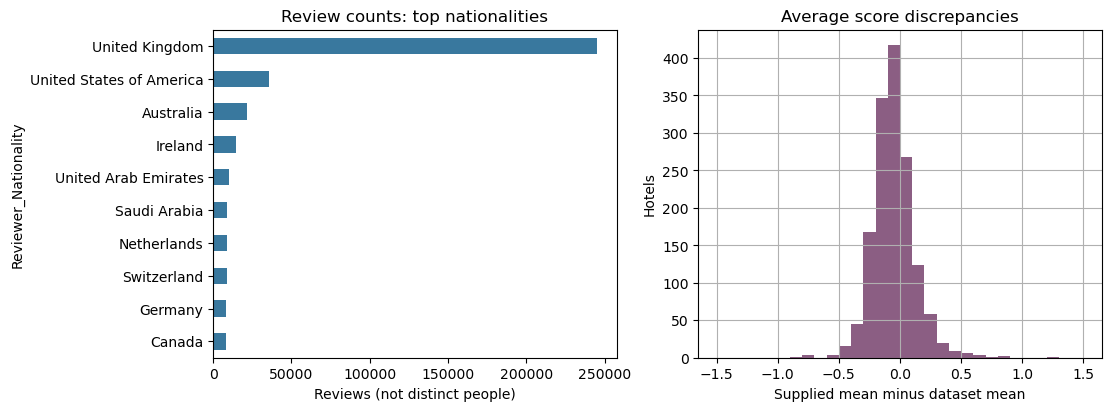

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
nationalities.head(10).sort_values().plot.barh(ax=axes[0], color='#39789e', title='Review counts: top nationalities')
axes[0].set_xlabel('Reviews (not distinct people)')
hotels.difference.hist(bins=np.arange(-1.5, 1.6, 0.1), ax=axes[1], color='#8b5e83')
axes[1].set(xlabel='Supplied mean minus dataset mean', ylabel='Hotels', title='Average score discrepancies')
fig.savefig('hotel-exploration.png', dpi=160)
plt.show()

## Challenge: sources of bias and skew

Compare this hotel dataset with the supplied movie-review corpus used in the
next lesson. Hotels are restricted to six European cities and the observed
nationality distribution is uneven. Counts describe reviews, not independent
people; reviewer IDs are absent. Nationality is unsuitable as an assumed
cause of sentiment or a basis for stereotyped recommendations. Identical
hotel names can identify different properties, so the next notebook groups
by the original name/address pair before abbreviating addresses.

The positive/negative field headings are not sentiment ground truth, and
placeholders are missing text rather than neutral experiences. Hotel scores
are bounded at 2.5–10; rescaling them does not create calibrated sentiment
labels. A repeated hotel average refers to a different aggregation and
cannot be checked using unobserved reviews.

The movie corpus is balanced deliberately, contains longer reviews, and has
rating-derived binary labels. That differs from hotel feedback and limits
cross-domain claims. Preserve Unicode, punctuation, and negation; inspect
malformed encodings rather than discarding non-English characters. The
[separate NLTK exercises](nltk-exercises.ipynb) complete the assignment.